# **FA 3 — Building SVM Model**
##### *Dela Cruz, Cloie Sofia* | *Zabala, Ralf Cedric*

# **SVM Model Code**

In [ ]:
# This line imports the NumPy library that supports mathematical equations, dimensional array, and matrices.
# In addition, this provides a colection of mathematical functions to operate on the data structures efficiently,
import numpy as np

# This import supports tha Pandas library, which is very well known for data manipulation and analysis through dataframes.
# As usual, this helps us to work with the dataframes and the dataset in understanding the data and processing it for the model.
import pandas as pd

# This is the import for the plots and maps of Python.
# This is very well known library to create visualizations as needed in this activity for better analysis and understanding.
import matplotlib.pyplot as plt

# This is the import that aids in the data modeling in this activity, especially the train-test split.
# The functions included here help in evaluating the model performance through cross-validation and hyperparameter tuning as well.
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score

# This import is for creating the pipeline that encloses the multiple steps involved in training the data through the SVM model.
# Basically, this ensures that data transformationa and model fitting are correctly executed in proper sequence.
from sklearn.pipeline import Pipeline

# This line imports the needed library for feature scaling and encoding labels from categorical data to numerical data.
# As SVM uses kernel functions, they require the features and the target to be numerical (GeeksforGeeks, 2021).
from sklearn.preprocessing import StandardScaler, LabelEncoder

# This is the import for the core algorithm that will be used in this activity.
# This is mainly used to create an SVM model
from sklearn.svm import SVC

# Imports evaluation metrics and includes reports and matrices for classification performance
# Tools that aid in interpretation of predictions such as accuracy and F1 scores
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)

# Imports feature selection tools
# Helps pick the most relevant features
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA

In [ ]:
# Today, our data is all about pollution, hence the .csv file name.
# In this dataset, our target column is Air Quality, which we will be predicting later on using the trained SVM model.
# The set data path will be the one used for loading the csv into a dataframe.
DATA_PATH = "updated_pollution_dataset.csv"

# This defines the target column name
# Through this we can clearly separate labels from features
TARGET_COL = "Air Quality"

# Loads the CSV into a DataFrame and reads the dataset from the file path
# Produces a structured table for EDA
df = pd.read_csv(DATA_PATH)

# This sets a fixed random state / This ensures reproducible results
# This keeps splits consistent each run / This helps fair comparisons across models
RANDOM_STATE = 42

# Define the test size
# This sets 20 percent of data for testing
TEST_SIZE = 0.20

### **Exploratory Data Analysis & Data Preparation**

In [ ]:
# This simple shows us what the table and its values look like from the first five (5) values.
# In a way, we get an idea on the features, the target, and its data type.
df.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


In [ ]:
# Show summary statistics of the dataset
# This gives an overview of feature distributions
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,5000.0,30.029020,6.720661,13.40,25.10,29.00,34.000,58.60
Humidity,5000.0,70.056120,15.863577,36.00,58.30,69.80,80.300,128.10
PM2.5,5000.0,20.142140,24.554546,0.00,4.60,12.00,26.100,295.00
PM10,5000.0,30.218360,27.349199,-0.20,12.30,21.70,38.100,315.80
NO2,5000.0,26.412100,8.895356,7.40,20.10,25.30,31.900,64.90
SO2,5000.0,10.014820,6.750303,-6.20,5.10,8.00,13.725,44.90
CO,5000.0,1.500354,0.546027,0.65,1.03,1.41,1.840,3.72
Proximity_to_Industrial_Areas,5000.0,8.425400,3.610944,2.50,5.40,7.90,11.100,25.80
Population_Density,5000.0,497.423800,152.754084,188.00,381.00,494.00,600.000,957.00


In [ ]:
# As part of the EDA, we simply make sure that we are truly assuming the correct data for each column.
# Furthermore, this helps in summarizing through a simple table of all the features and their data type.
pd.DataFrame({
    "Columns": df.columns,
    "Data Type": df.dtypes.values
})

,Columns,Data Type
0,Temperature,float64
1,Humidity,float64
2,PM2.5,float64
3,PM10,float64
4,NO2,float64
5,SO2,float64
6,CO,float64
7,Proximity_to_Industrial_Areas,float64
8,Population_Density,int64
9,Air Quality,object


In [ ]:
# In here, we simply check for nulls as part of the data preparation in order to polish the dataset for training.
# With no missing values for any of the features, there is no need for any row drops or give them default values.
pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values
})

,Column,Missing Values
0,Temperature,0
1,Humidity,0
2,PM2.5,0
3,PM10,0
4,NO2,0
5,SO2,0
6,CO,0
7,Proximity_to_Industrial_Areas,0
8,Population_Density,0
9,Air Quality,0


In [ ]:
# Similar to the null checking, we simply check for duplicates.
# As seen from the result, no duplicate rows have been detected in the dataframe.
df.duplicated().sum()

np.int64(0)

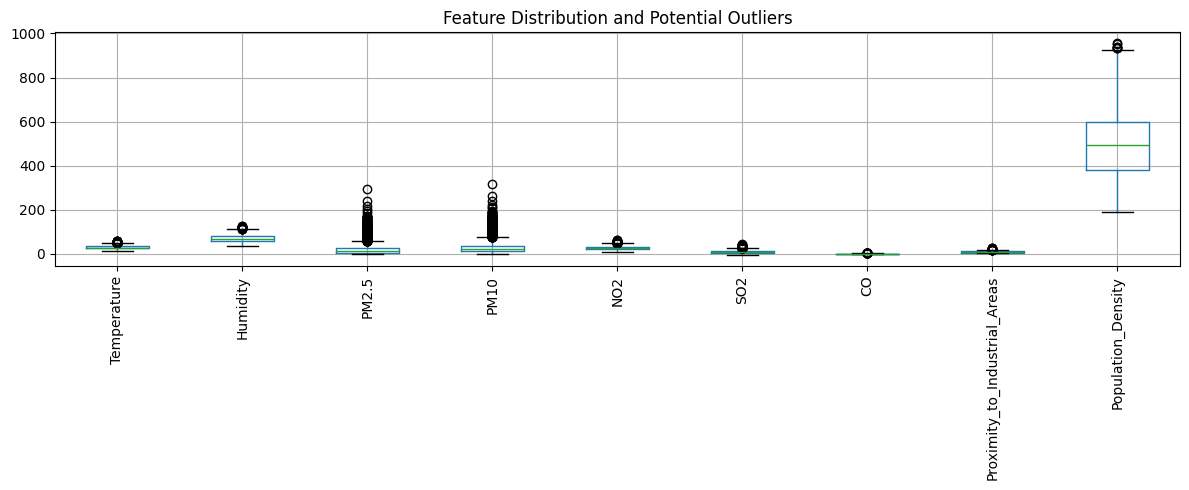

In [ ]:
# Select only numeric columns from the dataset
# This makes sure we only plot values that make sense numerically
X_num = df.select_dtypes(include=["number"])

# Create a boxplot for all numeric features
# This helps us see distributions and possible outliers
X_num.boxplot(rot=90, figsize=(12,5))

# Add a title to the plot
# This explains what the visualization is showing
plt.title("Feature Distribution and Potential Outliers")

# Adjust spacing so labels don’t overlap
# This makes the plot cleaner and easier to read
plt.tight_layout()

# Display the boxplot
# This renders the visualization on the screen
plt.show()


### **Data Loading**

In [ ]:
# Separate features from the target
# This removes the label column from input features
X_raw = df.drop(columns=[TARGET_COL])

# Extract the target column
# This stores the labels separately
y_raw = df[TARGET_COL]

# As SVM only allows numerical values, this only selects the numerical date among the features.
# This line is simply a safety net for the model to not encounter any errors.
X_num = X_raw.select_dtypes(include=[np.number]).copy()

# Encode target if it is text labels
# Check if the target values are text-based
# This determines if label encoding is needed
if y_raw.dtype == "object" or str(y_raw.dtype).startswith("category"):

    # Create a label encoder
    # This converts text labels into numbers
    le = LabelEncoder()

    # Encode the target labels
    # This makes the labels usable by the model
    y = le.fit_transform(y_raw.astype(str))

    # Store readable class names
    # These will be used for reports and plots
    class_names = [str(c) for c in le.classes_]
else:
    # If already numeric classes
    # Use target values directly
    # This applies if labels are already numeric
    y = y_raw.values

    # Store unique class names
    # This keeps labels organized for output
    class_names = sorted(list(pd.unique(y_raw)))



In [ ]:
# Despite being tasked to create 2 models, we will have one split to be able to differentiate the two with the features alone.
# Later on, we will be branching out to models 1 and 2.
X_train, X_test, y_train, y_test = train_test_split(
    X_num, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

> ## **SVM Model 1: Using 3 key features**



### **Feature Selection**



In [ ]:
# For feature selection, we will be using mutual information.
# While using a correlation analysis would be good, mutual information recognizes any kind of relationship, which extends correlational analysis that detect linear relationship only (Holbrook & Cook, 2023).
mi_train = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

# This sorts the features from the results of mutual information, from highest to lowest.
# Then, the top 3 features will be displayed and utilized on the first model.
mi_scores = pd.Series(mi_train, index=X_train.columns).sort_values(ascending=False)

# Select the top 3 features
# These will be used for Model 1
top3_features = mi_scores.head(3).index.tolist()

# Simply for transparency, the scores will be printed.
# We can easily see here the top 3 features that is related with the target and every feature that follows.
print("Top 3 selected features (mutual information):", top3_features)
print("\nTop MI scores:\n", mi_scores.head(10))

# This saves the gathered features to variable X.
# Only three features will be used for training the model.
X_train1 = X_train[top3_features].copy()

# Create test data using top 3 features
# This ensures consistent evaluation
X_test1 = X_test[top3_features].copy()

Top 3 selected features (mutual information): ['CO', 'Proximity_to_Industrial_Areas', 'NO2']

Top MI scores:
 CO                               0.892626
Proximity_to_Industrial_Areas    0.744070
NO2                              0.479308
SO2                              0.444292
Temperature                      0.417751
Population_Density               0.328693
Humidity                         0.289898
PM10                             0.264641
PM2.5                            0.115655
dtype: float64


### **Data Modeling**

In [ ]:
# Build a pipeline with scaling and SVM
# This ensures preprocessing happens correctly
pipe = Pipeline([

    # Standardize feature values
    # This helps SVM perform better
    ("scaler", StandardScaler()),

    # Define the SVM classifier
    # Uses RBF kernel for non-linear patterns
    ("svm", SVC(kernel="rbf"))
    ])

# Define hyperparameters to tune
# These values control model complexity
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1]
    }

### **Hyperparameter Tuning**

In [ ]:
# Set up stratified cross-validation
# This keeps class distribution balanced
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Create GridSearch for Model 1
# This finds the best parameters for 3 features
grid1 = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

# Train Model 1 using GridSearch
# This fits multiple models and selects the best
grid1.fit(X_train1, y_train)

# Save the best trained Model 1
# This model will be used for prediction
best_model1 = grid1.best_estimator_

print("\nBest hyperparameters (Model 1):", grid1.best_params_)


Best hyperparameters (Model 1): {'svm__C': 100, 'svm__gamma': 'scale'}


In [ ]:
# Predict test data using Model 1
# This generates predicted class labels
y_pred1 = best_model1.predict(X_test1)

# Compute accuracy for Model 1
# This measures how many predictions were correct
acc1 = accuracy_score(y_test, y_pred1)

# Compute weighted F1 score for Model 1
# This balances precision and recall
f1w1 = f1_score(y_test, y_pred1, average="weighted")

# Display Model 1 results
# This prints accuracy and F1 score
print("\nMODEL 1 RESULTS (3 features)")
print("Accuracy:", acc1)
print("F1 (weighted):", f1w1)
print("\nClassification Report:\n", classification_report(y_test, y_pred1, target_names=[str(x) for x in class_names]))


MODEL 1 RESULTS (3 features)
Accuracy: 0.924
F1 (weighted): 0.9224238830219489

Classification Report:
               precision    recall  f1-score   support

        Good       0.99      1.00      1.00       400
   Hazardous       0.85      0.73      0.78       100
    Moderate       0.92      0.97      0.94       300
        Poor       0.83      0.81      0.82       200

    accuracy                           0.92      1000
   macro avg       0.90      0.88      0.88      1000
weighted avg       0.92      0.92      0.92      1000



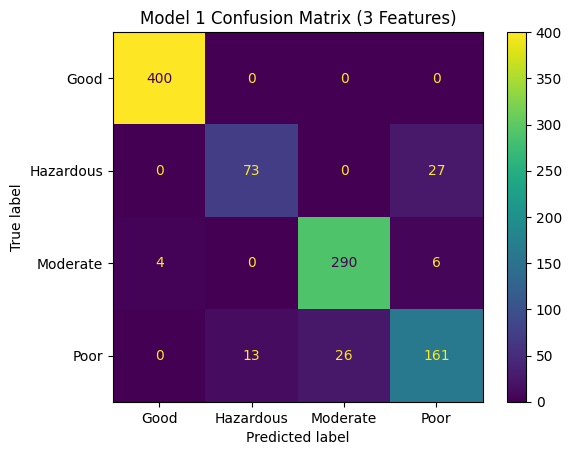

In [ ]:
# Confusion matrix

# Create confusion matrix for Model 1
# This compares true vs predicted labels
cm1 = confusion_matrix(y_test, y_pred1)

# Prepare confusion matrix display
# This makes plotting easier
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=[str(x) for x in class_names])

# Show confusion matrix for Model 1
# This visualizes classification performance
disp1.plot(values_format="d")
plt.title("Model 1 Confusion Matrix (3 Features)")
plt.show()

> ## **SVM Model 2: Using ALL features**

### **Data Modeling**

In [ ]:
# Create GridSearch for Model 2
# This will tune the model using all available features
grid2 = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

# Train Model 2 using all features
# This fits multiple models and selects the best one
grid2.fit(X_train, y_train)

# Save the best trained Model 2
# This model will be used for final evaluation
best_model2 = grid2.best_estimator_

print("\nBest hyperparameters (Model 2):", grid2.best_params_)


Best hyperparameters (Model 2): {'svm__C': 1, 'svm__gamma': 'scale'}


In [ ]:
# Predict test data using Model 2
# This generates predicted labels for evaluation
y_pred2 = best_model2.predict(X_test)

# Compute accuracy for Model 2
# This measures overall correctness
acc2 = accuracy_score(y_test, y_pred2)

# Compute weighted F1 score for Model 2
# This balances precision and recall across classes
f1w2 = f1_score(y_test, y_pred2, average="weighted")

# Display Model 2 results
# This prints the performance metrics
print("\nMODEL 2 RESULTS (All features)")
print("Accuracy:", acc2)
print("F1 (weighted):", f1w2)

# Print classification report for Model 2
# This shows precision, recall, and F1 per class
print("\nClassification Report:\n", classification_report(y_test, y_pred2, target_names=[str(x) for x in class_names]))


MODEL 2 RESULTS (All features)
Accuracy: 0.939
F1 (weighted): 0.9386356302044596

Classification Report:
               precision    recall  f1-score   support

        Good       0.99      0.99      0.99       400
   Hazardous       0.88      0.82      0.85       100
    Moderate       0.94      0.96      0.95       300
        Poor       0.86      0.86      0.86       200

    accuracy                           0.94      1000
   macro avg       0.92      0.91      0.91      1000
weighted avg       0.94      0.94      0.94      1000



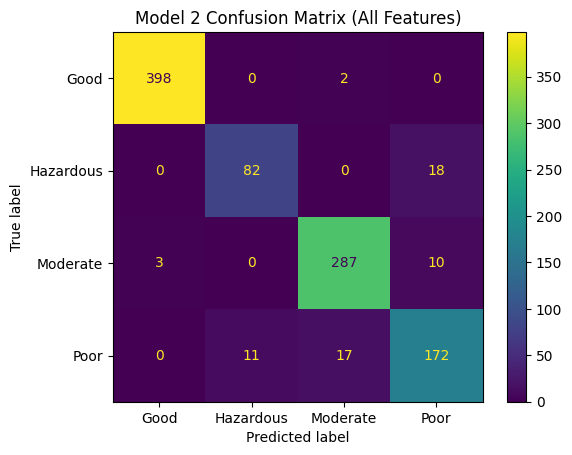

In [ ]:
# Confusion matrix for Model 2

# Create confusion matrix for Model 2
# This compares actual vs predicted classes
cm2 = confusion_matrix(y_test, y_pred2)

# Prepare confusion matrix display
# This makes plotting cleaner and easier
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=[str(x) for x in class_names])

# Plot confusion matrix for Model 2
# This visualizes classification performance
disp2.plot(values_format="d")

# Add title to the plot
# This clearly labels the visualization
plt.title("Model 2 Confusion Matrix (All Features)")

# Show the confusion matrix
# This renders the plot on screen
plt.show()


## **Visualizations & Comparisons**


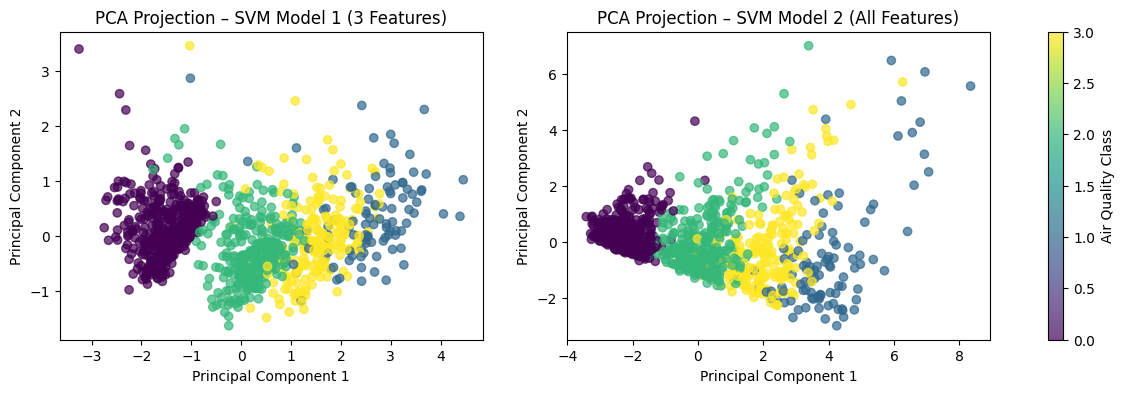

In [ ]:
# Create a scaler for Model 1
# This standardizes the 3 selected features
scaler1 = StandardScaler()

# Scale Model 1 training data
# This prepares data for PCA
X1_train_scaled = scaler1.fit_transform(X_train1)

# Scale Model 1 test data
# This keeps scaling consistent
X1_test_scaled = scaler1.transform(X_test1)

# Create PCA for Model 1
# This reduces features to two components
pca1 = PCA(n_components=2, random_state=42)

# Fit PCA on training data
# This learns the main directions of variance
pca1.fit(X1_train_scaled)

# Transform test data using PCA
# This projects data into 2D space
X1_pca = pca1.transform(X1_test_scaled)

# This is for the second PCA visualization for Model 2.
# Create a scaler for Model 2
# This standardizes all features
scaler2 = StandardScaler()


# Scale Model 2 training data
# This prepares data for PCA
X2_train_scaled = scaler2.fit_transform(X_train)

# Scale Model 2 test data
# This ensures consistent scaling
X2_test_scaled = scaler2.transform(X_test)

# Create PCA for Model 2
# This reduces all features to two components
pca2 = PCA(n_components=2, random_state=42)

# Fit PCA on Model 2 training data
# This learns the main variance directions
pca2.fit(X2_train_scaled)

# Transform Model 2 test data
# This projects data into PCA space
X2_pca = pca2.transform(X2_test_scaled)

# Plot side-by-side PCA
# Create a figure with two subplots
# This allows side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot PCA scatter for Model 1
# Shows how classes spread using only three features
scatter1 = axes[0].scatter(

    # Use the first principal component for the x-axis
    # Represents the strongest direction of variance
    X1_pca[:, 0],

    # Use the second principal component for the y-axis
    # Captures the next most important variance
    X1_pca[:, 1],

    # Color points based on true class labels
    # Makes it easier to see class groupings
    c=y_test,

    # Apply the viridis color palette
    # Keeps colors consistent across both plots
    cmap='viridis',

    # Set transparency for better overlap visibility
    # Helps reveal dense or overlapping points
    alpha=0.7
)

# Set title for Model 1 PCA plot
# Clearly identifies the model and feature count
axes[0].set_title("PCA Projection – SVM Model 1 (3 Features)")

# Label the x-axis
# Indicates the first principal component
axes[0].set_xlabel("Principal Component 1")

# Label the y-axis
# Indicates the second principal component
axes[0].set_ylabel("Principal Component 2")

# Plot PCA scatter for Model 2
# Shows class distribution using all features
scatter2 = axes[1].scatter(

    # Use the first principal component for the x-axis
    # Represents the strongest direction of variance
    X2_pca[:, 0],

    # Use the second principal component for the y-axis
    # Captures the next most important variance
    X2_pca[:, 1],

    # Apply the same color palette
    # Makes visual comparison easier
    c=y_test, cmap='viridis',

    # Set transparency for overlapping points
    # Improves readability in dense regions
    alpha=0.7
)

# Set title for Model 2 PCA plot
# Highlights that all features are used
axes[1].set_title("PCA Projection – SVM Model 2 (All Features)")

# Label the x-axis
# Indicates the first principal component
axes[1].set_xlabel("Principal Component 1")

# Label the y-axis
# Indicates the second principal component
axes[1].set_ylabel("Principal Component 2")

# Add a shared colorbar for both plots
# Maps colors to air quality classes
plt.colorbar(scatter2, ax=axes, label="Air Quality Class")

# Display the PCA comparison plots
# Finishes and renders the visualization
plt.show()

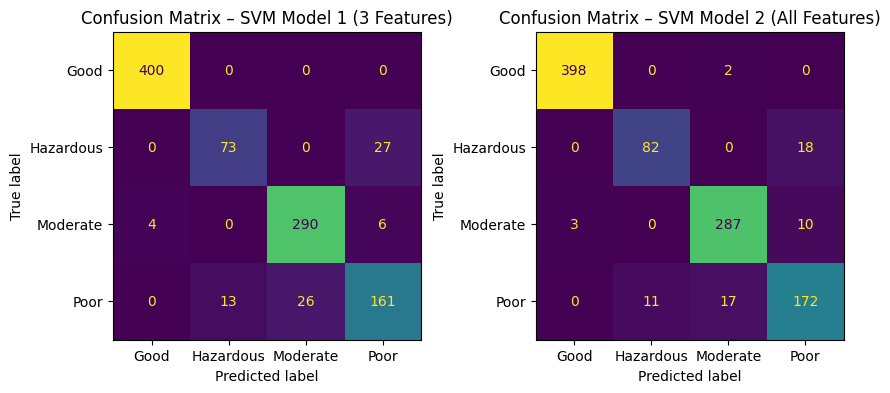

In [ ]:
# Create a figure with two side-by-side plots
# Makes it easier to compare both models at once
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Model 1 confusion matrix
# Plot confusion matrix for Model 1
# Shows prediction performance using three features
disp1.plot(ax=axes[0], values_format="d", colorbar=False)

# Set title for Model 1 confusion matrix
# Clearly labels the model and feature setup
axes[0].set_title("Confusion Matrix – SVM Model 1 (3 Features)")

# Model 2 confusion matrix
# Plot confusion matrix for Model 2
# Shows prediction performance using all features
disp2.plot(ax=axes[1], values_format="d", colorbar=False)

# Set title for Model 2 confusion matrix
# Clearly labels the model and feature setup
axes[1].set_title("Confusion Matrix – SVM Model 2 (All Features)")

# Display both confusion matrices
# Renders the side-by-side comparison
plt.show()

# **Discussion**

---
> ## **SVM Model 1**

Model 1 highlights three (3) key features as determined by Mutual Information. This is a technique in feature selection that determines the most related features to the target, measuring informational gain between inputs and air quality classes (Hayet-Otero et al., 2023; Kim et al., 2024). This was chosen due to its nature to detect beyond the linear relationships that correlational analysis detects with the target (Holbrook & Cook, 2023). With the task of choosing 3 key features, this feature selection determines the most impactful attributes that contribute to the decision of the air quality. As a limited number of features is only allowed, these carefully selected features aid in reducing the model complexity and at the same time still achieving high accuracies in predicting the air quality.

The PCA visualization, which utilizes the split and the three (3) features from the test data, presents a visible separation between the range of classes from high to low, a method proven effective for diagnosing class distribution in environmental datasets (Chatterjee et al., 2024; Makala, 2025). Despite this, overlaps are still very noticeable between intermediate classes. This tells us that the limited features is not enough to grasp the complexity of the variations of air quality. Also, the overlap shows that multiple classes share similar patterns with the reduced feature space, making them difficult to differentiate using only three variables.

The confusion matrix supports this with evident misclassification among adjacent air quality categories compared to the second model. Among these observation, the model is evidently performing sufficiently for extreme cases but confuses classes when there are subtle differences among them.

In conclusion, with a 92.4% accuracy, Model 1 presents itself as a strong lightweight model that demonstrates that carefully selected features specifically mutual information contributes in class distinction, however, additional features are necessary in order to improve the class discrimination and prediction.

---

> ## **SVM Model 2**

Model 2 highlights all the features provided in the dataset. With the extended feature space, more complexities were captured among the attributes of air quality that were not included in Model 1. This added dimensionality allows the model to utilize the RBF kernel that is designed for non-linear decision boundaries.

The PCA visualization for this one presents a clearer class separation with less overlaps and clusters towards the first principal component. With better class distinctions, the additional features added in this model tell their contribution through their variations in the provided data that improves the accuracy of the model. 2D visualization supports this.

The confusion matrix further supports the enhanced performance of the model with less misclassifications among the target classes. The results points to the contribution of the added features to a more expressive decision boundary.

With a 93.9% accuracy for the second model, overall, this presents a strong and more accurate model that utilizes all the given data, with a future possible improvement on its weights.

---

> ## **Both Models**
---

**On Processing**

This model shares the same data preparation and data split as SVM Model 2. Upon data exploration and analysis, no nulls or duplicates were found. Thus, no drops were done nor defaults were set. While outliers are evident from the boxplot visualization, these outliers are expected as these can range and spike from localized or unexpected events. No transformation or technique were applied as these data are highly meaningful for predicting the air quality.

Data loading both involved encoding the target labels to numerical data as they were initially objects, and the SVM algorithm only trains numerical data. Same splits were also applied to both models, as well as the pipeline that involved standardization. Hyperparameter tuning were also done to both models using GridSearchCV to optimize the RBF kernel parameters, which is critical for maximizing classification metrics like the F1-score (Emphan et al., 2026; Kurniasih & Previana, 2025), but to each of their own training data. The only difference in the processing and modeling were during the feature selection, in which Model 1 had three (3) key features as its training and test data and Model 2 utilized all the features from the given dataset.

**On Performance**

On its performance, the two models emphasizes the impact of feature dimensionality of classification performance. With three key features trained on Model 1, evident overlaps and limited separability in the PCA space are observed. While this is a lightweight model, this has limited ability to fully distinguish classes that have subtle differences.

Model 2, in contrast, highly benefits from the additional features that it involves compared to Model 1. As indicated earlier, even extreme outliers are important in predicting air quality, hence are more features also important in providing variance and accuracy in predicting air quality classes. The PCA visualization in this model shows clearer separated classes with reduced overlaps. This improvement aligns with the improved accuracy of the model albeit with a difference of 1.5% and the confusion matrix, which remains a standard metric for validating real-time environmental monitoring models (Shahid et al., 2024), indicated that the extended features improves the categorical separability and accuracy of the model.

Overall, the comparison of these two models demonstrates that a lightweight, accurate air quality classifcation model can be curated with appropriate feature selection, maintaining robustness even in high-dimensional pollutant spaces (Chatterjee et al., 2024; Makala, 2025), in relation to the target feature. While this model is a good baseline, broader and extended features that are highly information significantly improve the Support Vector Machine's ability to understand complex patterns. These findings emphasize the importance of balancing model simplicity with the enrichment of complexity representation when designing machine learning models.

---

# **References**

*   Chatterjee, D., Ghosh, P., Banerjee, A., & Das, S. S. (2024). Optimizing machine learning for water safety: A comparative analysis with dimensionality reduction and classifier performance in potability prediction. PLOS Water, 3(4), e0000259. https://doi.org/10.1371/journal.pwat.0000259
* Emphan, A., et al. (2026). Enhancing the performance of sentiment analysis models using GridSearchCV: A case study on electric vehicles in Thailand. Journal of Applied Informatics and Technology, 8(1), 260631. https://ph01.tci-thaijo.org/index.php/jait/article/view/260631

* Hayet-Otero, M., García-García, F., Lee, D.-J., Martínez-Minaya, J., España Yandiola, P. P., Urrutia Landa, I., Nieves Ermecheo, M., Quintana, J. M., Menéndez, R., Torres, A., Zalacain Jorge, R., & Arostegui, I. (2023). Extracting relevant predictive variables for COVID-19 severity prognosis: An exhaustive comparison of feature selection techniques. PLOS ONE, 18(4), e0284150. https://doi.org/10.1371/journal.pone.0284150

*   Holbrook, R., & Cook, A. (2023). Mutual Information. Kaggle.com. https://www.kaggle.com/code/ryanholbrook/mutual-information

* Kim, D., Lee, S., Park, I., Kim, G., & Kim, S. (2024). RecNet: Reinforcement common feature mapping network for fast template matching in visible-LWIR images. IEEE Access, 12, 195890-195905. https://doi.org/10.1109/access.2024.3520169

* Kurniasih, A., & Previana, C. N. (2025). Implementation of GridSearchCV to find the best hyperparameter combination for classification model algorithm in predicting water potability. Journal of Artificial Intelligence and Engineering Applications (JAIEA), 4(2), 1174-1182. https://doi.org/10.59934/jaiea.v4i2.844

* Makala, M. (2025). Forecasting of air quality with machine learning [Conference paper]. IAIA25 Conference, Calgary, Canada. https://2025.iaia.org/final-papers/1261_Makala_Forecasting_of_air_Quality.pdf

* Shahid, M. S. B., Rifat, H. R., Uddin, M. A., Islam, M. M., Mahmud, M. Z., Sakib, M. K. H., & Roy, A. (2024). Hypertuning-based ensemble machine learning approach for real-time water quality monitoring and prediction. Applied Sciences, 14(19), 8622. https://doi.org/10.3390/app14198622

